Upload image for Local Binary Pattern (LBP):


Saving sunset.jpg to sunset.jpg


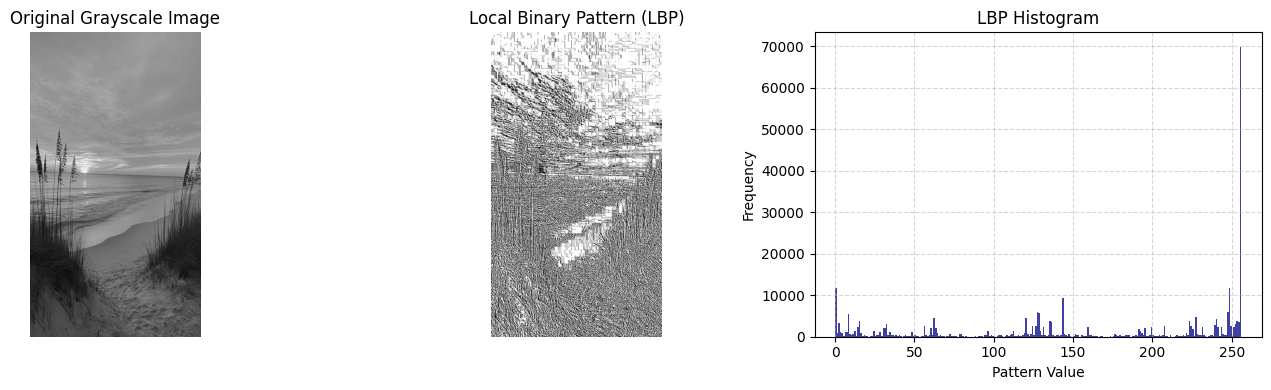

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

print("Upload image for Local Binary Pattern (LBP):")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

def compute_lbp(image):
    rows, cols = image.shape
    lbp_image = np.zeros((rows - 2, cols - 2), dtype=np.uint8)


    weights = [1, 2, 4, 8, 16, 32, 64, 128]

    offsets = [
        (-1, -1), (-1, 0), (-1, 1),
        (0, 1),   (1, 1),  (1, 0),
        (1, -1),  (0, -1)
    ]

    for i in range(1, rows - 1):
        for j in range(1, cols - 1):
            center = image[i, j]
            lbp_val = 0
            for idx, (dr, dc) in enumerate(offsets):
                neighbor = image[i + dr, j + dc]
                if neighbor >= center:
                    lbp_val |= weights[idx]
            lbp_image[i - 1, j - 1] = lbp_val

    return lbp_image

lbp_img = compute_lbp(img)

plt.figure(figsize=(14, 4))

plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original Grayscale Image')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(lbp_img, cmap='gray')
plt.title('Local Binary Pattern (LBP)')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.hist(lbp_img.ravel(), bins=256, range=[0, 256], color='navy', alpha=0.75)
plt.title('LBP Histogram')
plt.xlabel('Pattern Value')
plt.ylabel('Frequency')
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

Upload image for Denoising experiments:


Saving download.png to download.png


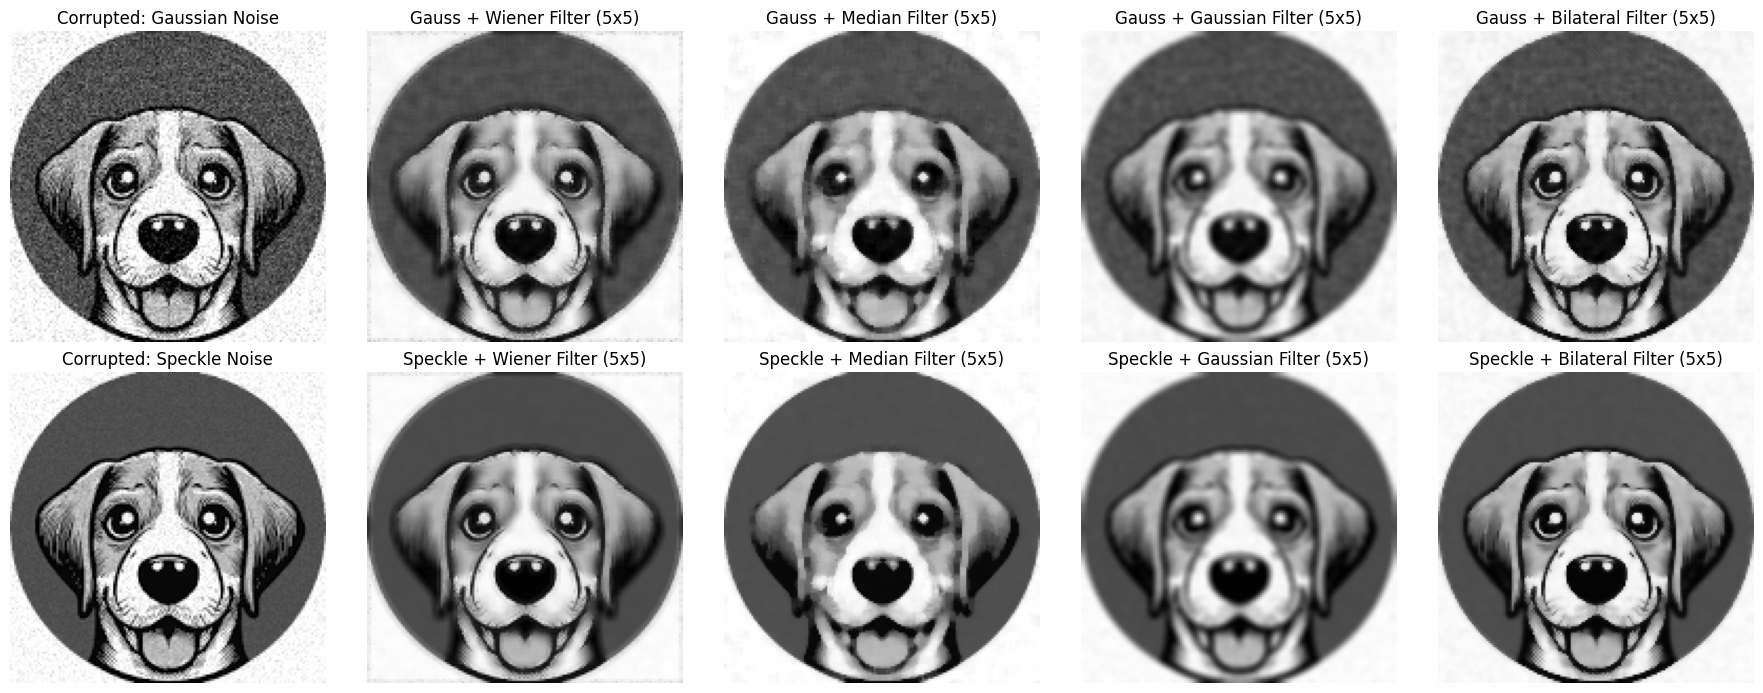

In [2]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import wiener
from google.colab import files

print("Upload image for Denoising experiments:")
uploaded = files.upload()
filename = list(uploaded.keys())[0]

img = cv2.imread(filename, cv2.IMREAD_GRAYSCALE)

mean = 0
sigma = 20
gauss_noise = np.random.normal(mean, sigma, img.shape)
noisy_gaussian = np.clip(img.astype(np.float64) + gauss_noise, 0, 255).astype(np.uint8)

speckle_noise = np.random.normal(0, 0.05, img.shape)
noisy_speckle = np.clip(img.astype(np.float64) + (img.astype(np.float64) * speckle_noise), 0, 255).astype(np.uint8)


def apply_filters(noisy_img):
    ksize = 5

    denoised_wiener = wiener(noisy_img.astype(np.float64), (ksize, ksize))
    denoised_wiener = np.clip(denoised_wiener, 0, 255).astype(np.uint8)

    denoised_median = cv2.medianBlur(noisy_img, ksize)

    denoised_gauss = cv2.GaussianBlur(noisy_img, (ksize, ksize), sigmaX=1.5)

    denoised_bilateral = cv2.bilateralFilter(noisy_img, d=ksize, sigmaColor=75, sigmaSpace=75)

    return [denoised_wiener, denoised_median, denoised_gauss, denoised_bilateral]

filtered_gaussian = apply_filters(noisy_gaussian)
filtered_speckle = apply_filters(noisy_speckle)

filter_names = [
    'Wiener Filter (5x5)',
    'Median Filter (5x5)',
    'Gaussian Filter (5x5)',
    'Bilateral Filter (5x5)'
]


fig, axes = plt.subplots(2, 5, figsize=(18, 7))

axes[0, 0].imshow(noisy_gaussian, cmap='gray')
axes[0, 0].set_title('Corrupted: Gaussian Noise')
axes[0, 0].axis('off')

for i in range(4):
    axes[0, i + 1].imshow(filtered_gaussian[i], cmap='gray')
    axes[0, i + 1].set_title(f'Gauss + {filter_names[i]}')
    axes[0, i + 1].axis('off')

axes[1, 0].imshow(noisy_speckle, cmap='gray')
axes[1, 0].set_title('Corrupted: Speckle Noise')
axes[1, 0].axis('off')

for i in range(4):
    axes[1, i + 1].imshow(filtered_speckle[i], cmap='gray')
    axes[1, i + 1].set_title(f'Speckle + {filter_names[i]}')
    axes[1, i + 1].axis('off')

plt.tight_layout()
plt.show()